In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from selenium import webdriver
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.common.by import By
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from selenium.webdriver.chrome.options import Options

# Path ke ChromeDriver
chrome_driver_path = "/Applications/MAMP/htdocs/local/kodingakademi/Python/python 3/final_ds/chromedriver-mac-arm64/chromedriver"

# Konfigurasi opsi Chrome
options = Options()
options.add_argument("--headless=new")  # Jalankan tanpa membuka jendela browser
options.add_argument("--disable-gpu")   # Mengurangi penggunaan GPU
options.add_argument("--no-sandbox")    # Untuk eksekusi di server tanpa GUI
options.add_argument("--disable-dev-shm-usage")  # Untuk menghindari error pada sistem berbasis Linux

# Inisialisasi WebDriver
service = Service(chrome_driver_path)
driver = webdriver.Chrome(service=service, options=options)

# Buka halaman Yahoo Finance
driver.get("https://finance.yahoo.com/quote/BBCA.JK/history/?p=BBCA.JK")

# Tunggu hingga tabel muncul
table = WebDriverWait(driver, 10).until(
    EC.presence_of_element_located((By.CLASS_NAME, "table"))
)

# Ambil semua baris tabel
rows = table.find_elements(By.TAG_NAME, "tr")

data = []
for row in rows:
    cols = row.find_elements(By.TAG_NAME, "td")
    if len(cols) == 7:
        date = cols[0].text 
        open = cols[1].text
        high = cols[2].text 
        low = cols[3].text  
        close = cols[4].text
        adj_close = cols[5].text  
        volume = cols[6].text  
        data.append([date, open, high, low, close, adj_close, volume])

# Simpan dalam DataFrame Pandas
df = pd.DataFrame(data, columns=["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"])

# Tutup browser
driver.quit()

In [2]:
df_backup = df.copy()

In [3]:
# 1. Konversi ke string dulu agar aman
df_backup['Date'] = df_backup['Date'].astype(str)

# 2. Buang baris yang mengandung teks yang bukan tanggal (contoh: "Dividend", "Stock Split", dll)
# Ini akan hanya menyisakan baris dengan pola format tanggal seperti 'Apr 30, 2025'
df_backup = df_backup[df_backup['Date'].str.match(r'^[A-Za-z]{3,} \d{1,2}, \d{4}$', na=False)]

df_backup['Date'] = pd.to_datetime(df_backup['Date'], format='%b %d, %Y')

# Bersihkan dan konversi kolom numerik
cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]
for col in cols:
    df_backup[col] = df_backup[col].str.replace(',', '', regex=False).astype(float)

# Urutkan dan reset index
df_backup = df_backup.sort_values('Date').reset_index(drop=True)

# Cek hasil
df_backup.to_csv("bbca.csv", index=False)


In [43]:
df = pd.read_csv("bbca.csv")
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,2024-05-15,9500.0,9600.0,9425.0,9500.0,9170.68,54741900.0
1,2024-05-16,9575.0,9675.0,9525.0,9600.0,9267.21,61126000.0
2,2024-05-17,9600.0,9850.0,9575.0,9750.0,9412.01,99848500.0
3,2024-05-20,9700.0,9800.0,9475.0,9475.0,9146.54,87890100.0
4,2024-05-21,9450.0,9575.0,9375.0,9375.0,9050.01,75311400.0
...,...,...,...,...,...,...,...
233,2025-05-07,9075.0,9100.0,9000.0,9075.0,9075.00,77382000.0
234,2025-05-08,9075.0,9200.0,8925.0,8975.0,8975.00,99614500.0
235,2025-05-09,9050.0,9050.0,8975.0,9000.0,9000.00,47167500.0
236,2025-05-14,9250.0,9300.0,9150.0,9275.0,9275.00,149002900.0


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.neighbors import KNeighborsRegressor

x = df[["Open","High","Low"]]
y = df[["Close"]]

scaler_x = MinMaxScaler()
x_scaled = scaler_x.fit_transform(x)

scaler_y = MinMaxScaler()
y_norm = scaler_y.fit_transform(y).ravel()

x_train, x_test, y_train, y_test = train_test_split(x_scaled, y_norm, test_size=0.2, random_state=42)

In [45]:
model_linear = LinearRegression()
model_dt = DecisionTreeRegressor(random_state=42)
model_rf = RandomForestRegressor(n_estimators=100, random_state=42)

model_linear.fit(x_train, y_train)
model_dt.fit(x_train, y_train)
model_rf.fit(x_train, y_train)

y_pred_linear = model_linear.predict(x_test)
y_pred_dt = model_dt.predict(x_test)
y_pred_rf = model_rf.predict(x_test)

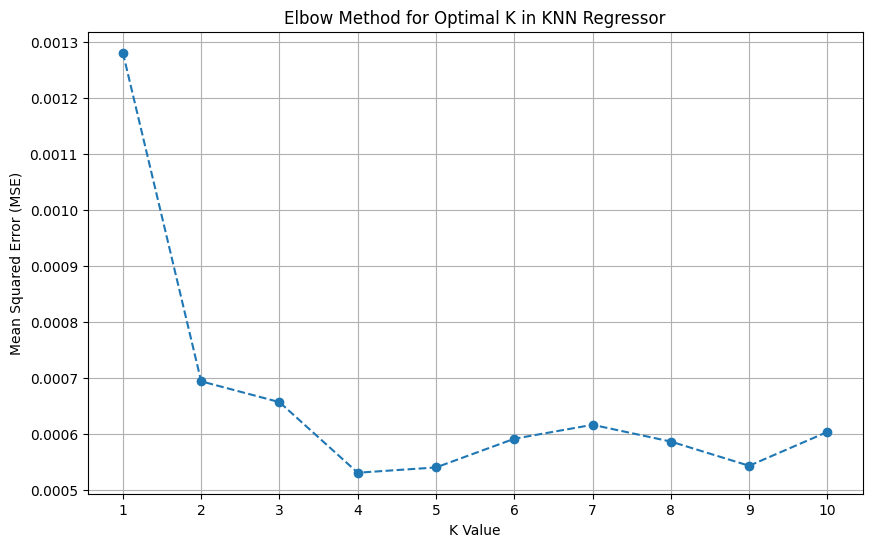

In [46]:
from sklearn.metrics import mean_squared_error

error_rate = []

# Uji k dari 1 sampai 10
for k in range(1, 11): # k = 1
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(x_train, y_train)
    pred_k = model.predict(x_test)
    error = mean_squared_error(y_test, pred_k)  # gunakan MSE
    error_rate.append(error)

# Plot Elbow
plt.figure(figsize=(10,6))
plt.plot(range(1, 11), error_rate, marker='o', linestyle='--')
plt.title('Elbow Method for Optimal K in KNN Regressor')
plt.xlabel('K Value')
plt.ylabel('Mean Squared Error (MSE)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [47]:
model_knn = KNeighborsRegressor(n_neighbors=4)
model_knn.fit(x_train, y_train)

y_pred_knn = model_knn.predict(x_test)

In [48]:
y_test_orig = scaler_y.inverse_transform(y_test.reshape(-1, 1)).ravel()
y_actual_linear = scaler_y.inverse_transform(y_pred_linear.reshape(-1, 1)).ravel()
y_actual_rf = scaler_y.inverse_transform(y_pred_rf.reshape(-1, 1)).ravel()
y_actual_dt= scaler_y.inverse_transform(y_pred_dt.reshape(-1, 1)).ravel()
y_actual_knn= scaler_y.inverse_transform(y_pred_knn.reshape(-1, 1)).ravel()

results_df = pd.DataFrame({
    'Actual': y_test_orig,
    'Predicted linear': y_actual_linear,
    'Predicted random forest': y_actual_rf,
    'Predicted decision tree': y_actual_dt,
    'Predicted knn': y_actual_knn,
})

results_df.head()

,Actual,Predicted linear,Predicted random forest,Predicted decision tree,Predicted knn
0,10350.0,10377.684556,10370.25,10350.0,10368.75
1,9325.0,9342.581027,9418.00,9450.0,9381.25
2,8525.0,8578.892831,8446.00,8425.0,8400.00
3,10100.0,10097.361698,10083.50,10075.0,10112.50
4,9300.0,9338.767582,9303.75,9300.0,9312.50


In [49]:
print(f"Linear regression : {model_linear.score(x_test, y_test)}")
print(f"Decision Tree : {model_dt.score(x_test, y_test)}")
print(f"Random Forest : {model_rf.score(x_test, y_test)}")
print(f"KNN : {model_knn.score(x_test, y_test)}")

Linear regression : 0.9911408376708175
Decision Tree : 0.9705586061408982
Random Forest : 0.9860153151385694
KNN : 0.9891363769627045
